# Detecção de Áudio Falso (ASVSpoof) - Notebook

**Objetivo:** treinar e avaliar classificadores de Machine Learning para identificar, de forma binária, se um áudio é **legítimo (bonafide)** ou um **ataque de falsificação (spoof)**.
 
**Resumo do pipeline**
 
| Etapa | O que é feito |
|---|---|
| 1. Ambiente | Instalação de bibliotecas e montagem do Google Drive |
| 2. Dataset | Leitura remota do ZIP do Kaggle e construção de um subconjunto balanceado (300 + 300) |
| 3. Features | Extração de 68 features acústicas por áudio (pyAudioAnalysis) |
| 4. EDA | Comparação visual e numérica entre as classes |
| 5. Modelos | Regressão Logística, Random Forest e SVM, com validação cruzada |
| 6. Avaliação | Acurácia no teste, matrizes de confusão e importância das features |
 

### Preparação do Ambiente e Obtenção do Dataset

1. **Instalamos as dependências**: `remotezip` (leitura parcial de ZIPs remotos), `librosa` e `pydub` (áudio), `scikit-learn`, `imbalanced-learn`, `seaborn` e `plotly` (modelagem e gráficos). O `ffmpeg` e as bibliotecas `portaudio` são exigidos pelo pyAudioAnalysis.
2. **Clonamos o repositório do pyAudioAnalysis** e o adicionamos ao `sys.path`, para importar seus módulos de extração de features.
3. **Montamos o Google Drive** para persistir os dados entre sessões.
4. **Criamos a estrutura de pastas** `dataset_balanceado/bonafide` e `dataset_balanceado/spoof`.

In [4]:
!pip install -q remotezip
!apt-get install -y ffmpeg libasound-dev portaudio19-dev libportaudio2 libportaudiocpp0
!pip install -q imbalanced-learn scikit-learn seaborn plotly librosa pydub

!git clone https://github.com/tyiannak/pyAudioAnalysis.git
import sys
sys.path.insert(0, '/content/pyAudioAnalysis')

import os
import random
import shutil
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from remotezip import RemoteZip
from google.colab import drive

drive.mount('/content/drive')

PASTA_PROJETO = Path('/content/drive/MyDrive/IA_Adversarial_ASVSpoof')
PASTA_SUBSET = PASTA_PROJETO / 'dataset_balanceado'

for subpasta in ['bonafide', 'spoof']:
    (PASTA_SUBSET / subpasta).mkdir(parents=True, exist_ok=True)

print(f"Estrutura pronta em: {PASTA_SUBSET}")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'libasound2-dev' instead of 'libasound-dev'
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
libasound2-dev is already the newest version (1.2.11-1ubuntu0.3).
portaudio19-dev is already the newest version (19.6.0-1.2build3).
libportaudio2 is already the newest version (19.6.0-1.2build3).
libportaudiocpp0 is already the newest version (19.6.0-1.2build3).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
fatal: destination path 'pyAudioAnalysis' already exists and is not an empty directory.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Estrutura pronta em: /content/drive/MyDrive/IA_Adversarial_ASVSpoof/dataset_balanceado


## Criação um subconjunto balanceado

O dataset é obtido do Kaggle (`ulianazb/asvspoof-2024`). Como o arquivo é muito grande, usamos o **`RemoteZip`**, que permite listar e extrair arquivos individuais do ZIP sem baixá-lo por inteiro.
  
1. **Resolvemos a URL de download** (o Kaggle redireciona para um link do Google Cloud Storage).
2. **Listamos o conteúdo do ZIP** e separamos os arquivos de áudio (`.flac`, `.wav`, ...) dos arquivos de metadados (`.txt`, `.csv`, ...).
3. **Identificamos a classe de cada áudio.** Primeiro tentamos pelo caminho do arquivo; como ele não contém a palavra *bonafide* ou *spoof*, lemos os **arquivos de protocolo/metadados** e associamos cada linha ao respectivo áudio.
4. **Balanceamos as classes**: sorteamos `N = 300` amostras de cada classe (`random.seed(42)` garante reprodutibilidade).
5. **Baixamos somente as amostras sorteadas** para o Drive e geramos o arquivo `metadata_balanceado.csv` (nome do arquivo, rótulo, alvo numérico e caminho).
**Resultado:** 300 áudios bonafide + 300 áudios spoof = 600 amostras, a partir de 50.131 bonafide e 273.176 spoof identificados.

In [7]:
url_kaggle = "https://www.kaggle.com/api/v1/datasets/download/ulianazb/asvspoof-2024"
with requests.get(url_kaggle, stream=True) as r:
    r.raise_for_status()
    url_remota_gcs = r.url

with RemoteZip(url_remota_gcs) as rz:
    todos_arquivos = rz.namelist()

print(f"Total de arquivos no pacote do Kaggle: {len(todos_arquivos)}")

EXTENSOES_AUDIO = {'.flac', '.wav', '.mp3', '.ogg'}
arquivos_meta = [f for f in todos_arquivos if Path(f).suffix.lower() in {'.tsv', '.txt', '.csv', '.json'}]
arquivos_audio = [f for f in todos_arquivos if Path(f).suffix.lower() in EXTENSOES_AUDIO]

print(f"Total de áudios encontrados: {len(arquivos_audio)}")
print("Exemplos de caminhos de áudio:", arquivos_audio[:5])
print("Arquivos de protocolo/metadados encontrados:", arquivos_meta[:10])

N_AMOSTRAS_POR_CLASSE = 300
random.seed(42)

mapa_audios_zip = {}
audios_por_classe = {'bonafide': [], 'spoof': []}

for caminho_zip in arquivos_audio:
    p = Path(caminho_zip)
    mapa_audios_zip[p.stem] = caminho_zip
    mapa_audios_zip[p.name] = caminho_zip

    partes_lower = caminho_zip.lower()
    if 'bonafide' in partes_lower or 'real' in partes_lower:
        audios_por_classe['bonafide'].append(caminho_zip)
    elif 'spoof' in partes_lower or 'fake' in partes_lower:
        audios_por_classe['spoof'].append(caminho_zip)

with RemoteZip(url_remota_gcs) as rz:
    if not audios_por_classe['bonafide'] or not audios_por_classe['spoof']:
        print("Lendo arquivos de protocolo remotamente para identificar as classes...")
        for meta_zip in arquivos_meta:
            try:
                conteudo = rz.read(meta_zip).decode('utf-8', errors='ignore')
                for linha in conteudo.splitlines():
                    partes = linha.strip().replace(',', ' ').split()
                    if not partes:
                        continue
                    linha_lower = [x.lower() for x in partes]
                    classe = None
                    if 'bonafide' in linha_lower or 'bona-fide' in linha_lower:
                        classe = 'bonafide'
                    elif 'spoof' in linha_lower:
                        classe = 'spoof'

                    if classe:
                        for token in partes:
                            nome_limpo = Path(token).stem
                            if nome_limpo in mapa_audios_zip:
                                audios_por_classe[classe].append(mapa_audios_zip[nome_limpo])
                                break
            except Exception as e:
                print(f"Aviso ao ler {meta_zip}: {e}")

    bonafide_lista = list(dict.fromkeys(audios_por_classe['bonafide']))
    spoof_lista = list(dict.fromkeys(audios_por_classe['spoof']))
    print(f"Identificados -> Bonafide: {len(bonafide_lista)} | Spoof: {len(spoof_lista)}")

    n_final = min(N_AMOSTRAS_POR_CLASSE, len(bonafide_lista), len(spoof_lista))
    assert n_final > 0, "Nenhuma amostra associada. Verifique os nomes impressos na célula anterior."

    escolhidos_bonafide = random.sample(bonafide_lista, n_final)
    escolhidos_spoof = random.sample(spoof_lista, n_final)

    registros = []
    for classe, lista_zip in [('bonafide', escolhidos_bonafide), ('spoof', escolhidos_spoof)]:
        print(f"Baixando {len(lista_zip)} amostras da classe '{classe}'...")
        for caminho_interno in lista_zip:
            nome_arquivo = Path(caminho_interno).name
            destino_drive = PASTA_SUBSET / classe / nome_arquivo

            if not destino_drive.exists():
                with rz.open(caminho_interno) as src, open(destino_drive, 'wb') as dst:
                    shutil.copyfileobj(src, dst)

            registros.append({
                'filename': nome_arquivo,
                'label': classe,
                'target': 0 if classe == 'bonafide' else 1,
                'drive_path': str(destino_drive)
            })

df_subset = pd.DataFrame(registros)
df_subset.to_csv(PASTA_SUBSET / 'metadata_balanceado.csv', index=False)

print("\nConcluído! Subconjunto salvo no Google Drive.")
print(df_subset['label'].value_counts())

Total de arquivos no pacote do Kaggle: 324493
Total de áudios encontrados: 324491
Exemplos de caminhos de áudio: ['flac_D/flac_D/D_0000000001.flac', 'flac_D/flac_D/D_0000000022.flac', 'flac_D/flac_D/D_0000000043.flac', 'flac_D/flac_D/D_0000000064.flac', 'flac_D/flac_D/D_0000000085.flac']
Arquivos de protocolo/metadados encontrados: ['ASVspoof5.dev.metadata.txt', 'ASVspoof5.train.metadata.txt']
Lendo arquivos de protocolo remotamente para identificar as classes...
Identificados -> Bonafide: 50131 | Spoof: 273176
Baixando 300 amostras da classe 'bonafide'...
Baixando 300 amostras da classe 'spoof'...

Concluído! Subconjunto salvo no Google Drive.
label
bonafide    300
spoof       300
Name: count, dtype: int64


## Processamento e Extração de Features

Cada áudio é convertido em um **vetor numérico de tamanho fixo**, que pode ser usado por modelos de ML.
  
1. O áudio é carregado com `librosa` e reamostrado para **16 kHz**.
2. O `ShortTermFeatures` do **pyAudioAnalysis** divide o sinal em quadros (*frames*) de **50 ms**, com passo de **25 ms** (50% de sobreposição).
3. Para cada quadro são calculadas **34 features**, mais suas **34 derivadas (delta)**, totalizando **68 features**:

| Grupo | Features |
|---|---|
| Domínio do tempo | `zcr` (taxa de cruzamento por zero), `energy`, `energy_entropy` |
| Espectrais | `spectral_centroid`, `spectral_spread`, `spectral_entropy`, `spectral_flux`, `spectral_rolloff` |
| Cepstrais | `mfcc_1` a `mfcc_13` |
| Cromáticas | `chroma_1` a `chroma_12` e `chroma_std` |
| Delta | variação temporal de cada uma das anteriores (`delta ...`) |
 
4. Como cada áudio tem um número diferente de quadros, **tiramos a média ao longo do tempo** de cada feature, obtendo um vetor de 68 valores por áudio.
5. Os resultados são salvos em `features_extraidas.csv`. Arquivos que falharem na leitura são ignorados.

In [8]:
import librosa
from pyAudioAnalysis import ShortTermFeatures

df_meta = pd.read_csv(PASTA_SUBSET / 'metadata_balanceado.csv')
features_lista = []

print("Extraindo features acústicas...")
for idx, row in df_meta.iterrows():
    try:
        y, sr = librosa.load(row['drive_path'], sr=16000)
        # Janela de 50ms, passo de 25ms
        F, f_names = ShortTermFeatures.feature_extraction(y, sr, 0.050*sr, 0.025*sr)

        if F.size > 0:
            media_features = np.mean(F, axis=1)
            dict_features = {nome: valor for nome, valor in zip(f_names, media_features)}
            dict_features['label'] = row['label']
            dict_features['target'] = row['target']
            features_lista.append(dict_features)

    except Exception as e:
        pass # Ignora áudios corrompidos

    if (idx + 1) % 100 == 0:
        print(f"Processados {idx + 1}/{len(df_meta)}...")

df_features = pd.DataFrame(features_lista)
df_features.to_csv(PASTA_SUBSET / 'features_extraidas.csv', index=False)
print("Extração concluída!")

Extraindo features acústicas...
Processados 100/600...
Processados 200/600...
Processados 300/600...
Processados 400/600...
Processados 500/600...
Processados 600/600...
Extração concluída!


## Análise Exploratória

Antes de treinar modelos, verificamos se algumas features têm distribuições diferentes entre as classes.
 
- Selecionamos quatro features representativas (`zcr`, `energy`, `energy_entropy`, `mfcc_1`).
- Plotamos **boxplots por classe**, que mostram mediana, dispersão e outliers.
- Calculamos a **média por classe**.
**Como interpretar:** quanto menor a sobreposição entre as caixas de bonafide e spoof, mais discriminativa tende a ser a feature. Diferenças pequenas nas médias, com grande sobreposição, indicam que **nenhuma feature isolada separa bem as classes**, o que motiva o uso de modelos que combinem várias delas.

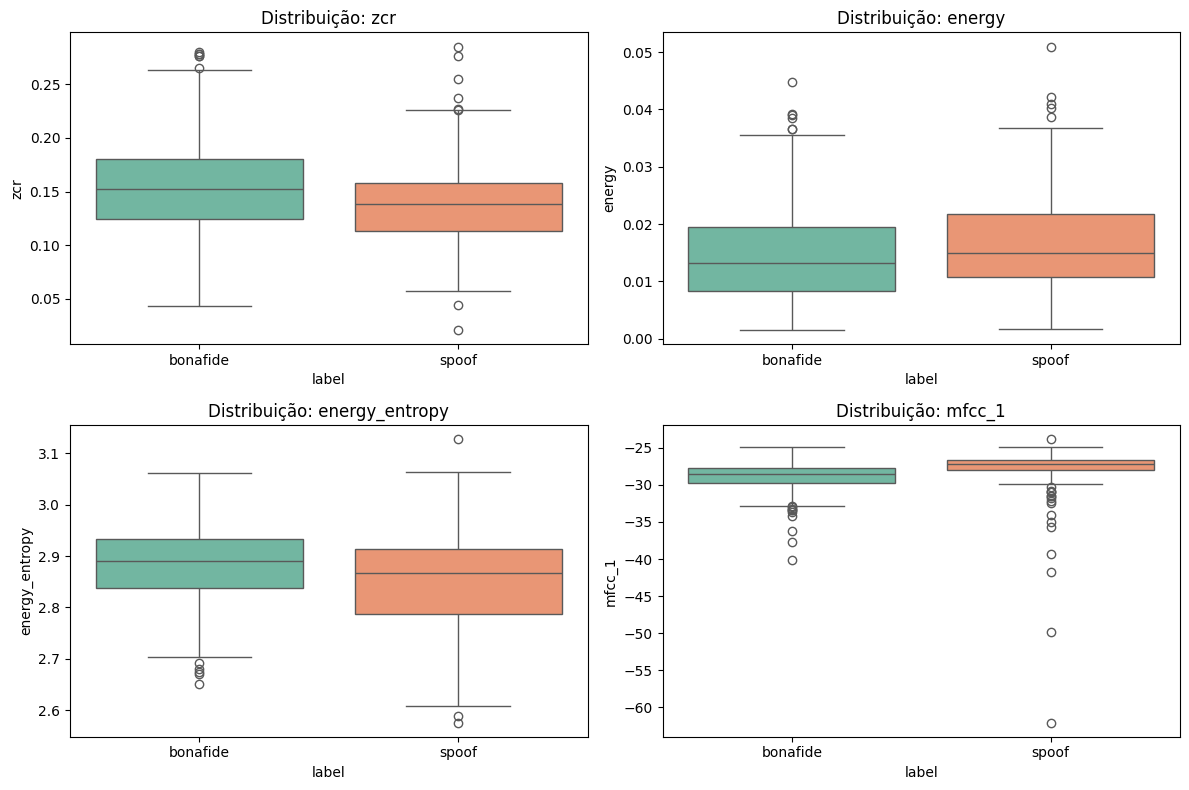


Médias por classe:


,zcr,energy,energy_entropy,mfcc_1
label,,,,
bonafide,0.154506,0.014449,2.883337,-28.805657
spoof,0.139123,0.016546,2.852111,-27.690819


In [9]:
cols_numericas = df_features.select_dtypes(include=[np.number]).columns
features_analise = ['zcr', 'energy', 'mfcc_1', 'mfcc_2']
features_reais = [c for c in cols_numericas if any(f in c for f in features_analise)][:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features_reais):
    sns.boxplot(x='label', y=col, data=df_features, ax=axes[i], palette='Set2', hue='label', legend=False)
    axes[i].set_title(f'Distribuição: {col}')

plt.tight_layout()
plt.savefig(PASTA_SUBSET / 'eda_boxplot.png')
plt.show()

print("\nMédias por classe:")
display(df_features.groupby('label')[features_reais].mean())

## Treinamento e Avaliação do Classificador

1. **Separação X / y**: `X` contém as 68 features; `y` é o alvo (0 = bonafide, 1 = spoof).
2. **Divisão treino/teste**: 80% / 20%, **estratificada** (mantém 50/50 de cada classe) e com `random_state=42`. Resultado: 480 amostras de treino e 120 de teste.
3. **Três modelos comparados:**
   - **Regressão Logística** — baseline linear;
   - **Random Forest** (100 árvores) — modelo não linear baseado em árvores;
   - **SVM** (kernel RBF padrão) — classificador por margem máxima.
4. **Validação cruzada de 5 folds** apenas no conjunto de treino, reportando média e desvio-padrão da acurácia. Isso estima a capacidade de generalização sem "gastar" o conjunto de teste.
5. **Avaliação final**: cada modelo é treinado em todo o treino e avaliado no teste (acurácia e **matriz de confusão**).
6. **Análise de sensibilidade**: ranking das 10 features mais importantes do Random Forest (*feature importances*), para saber quais características mais contribuem para a decisão.
**Resultados obtidos**
 
| Modelo | Acurácia (CV, treino) | Acurácia (teste) |
|---|---|---|
| Regressão Logística | 0,7083 ± 0,0600 | 0,7250 |
| Random Forest | 0,7479 ± 0,0553 | 0,7417 |
| SVM | 0,6771 ± 0,0401 | 0,7000 |

=== Resultados da Validação Cruzada (Treino) ===
Regressão Logística: Acurácia média = 0.7083 (Desvio: 0.0600)
Random Forest: Acurácia média = 0.7479 (Desvio: 0.0553)
SVM: Acurácia média = 0.6771 (Desvio: 0.0401)

=== Resultados Finais no Conjunto de Teste ===
Regressão Logística: Acurácia no Teste = 0.7250
Random Forest: Acurácia no Teste = 0.7417
SVM: Acurácia no Teste = 0.7000

--> Melhor classificador: Random Forest


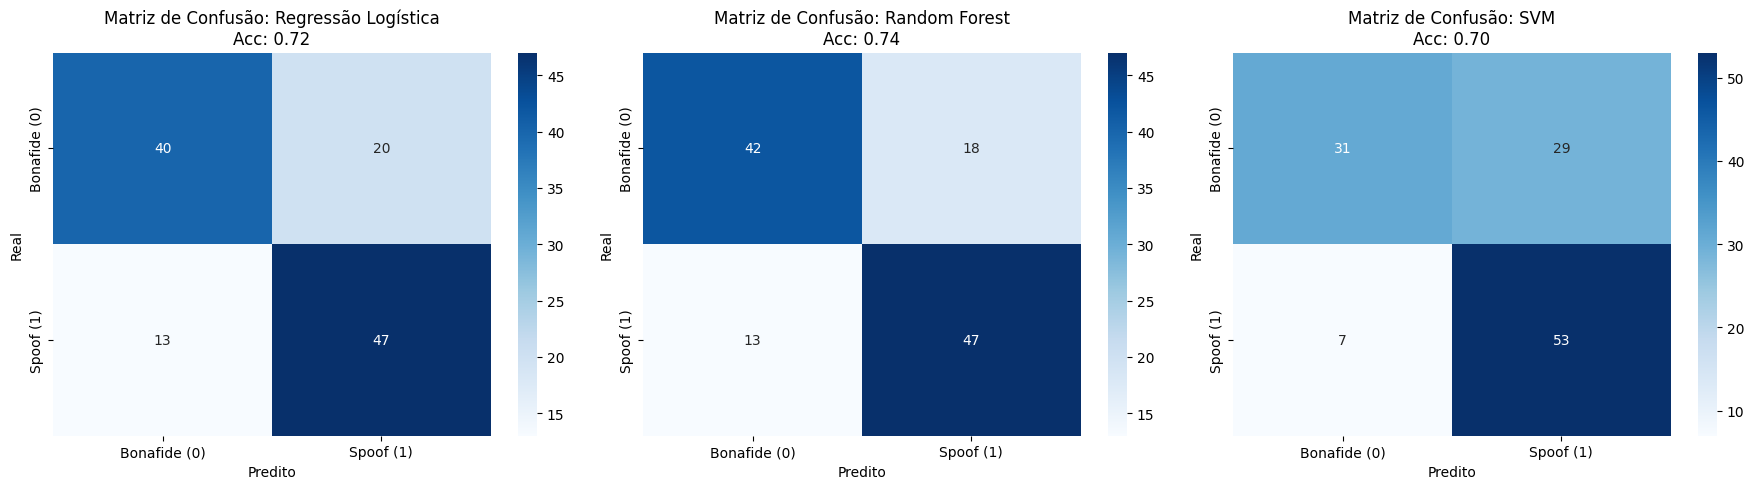


=== Análise de Sensibilidade: Top 10 Features mais importantes (Random Forest) ===


,Feature,Importância
8,mfcc_1,0.107898
14,mfcc_7,0.028005
5,spectral_entropy,0.027485
9,mfcc_2,0.025481
2,energy_entropy,0.025103
13,mfcc_6,0.024640
4,spectral_spread,0.021977
51,delta mfcc_10,0.021137
31,chroma_11,0.020740
12,mfcc_5,0.020208


In [10]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Separar X e y
X = df_features.drop(columns=['label', 'target', 'filename', 'drive_path'], errors='ignore')
y = df_features['target']

# Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Inicializar modelos
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(random_state=42)
}

# Validação Cruzada (Treino)
print("=== Resultados da Validação Cruzada (Treino) ===")
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring='accuracy')
    print(f"{nome}: Acurácia média = {scores.mean():.4f} (Desvio: {scores.std():.4f})")

# Treinamento Final e Teste
print("\n=== Resultados Finais no Conjunto de Teste ===")
resultados_teste = {}
predicoes = {}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    resultados_teste[nome] = acc
    predicoes[nome] = y_pred
    print(f"{nome}: Acurácia no Teste = {acc:.4f}")

melhor_modelo = max(resultados_teste, key=resultados_teste.get)
print(f"\n--> Melhor classificador: {melhor_modelo}")

# Plotar Matrizes de Confusão
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (nome, y_pred) in enumerate(predicoes.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Bonafide (0)', 'Spoof (1)'],
                yticklabels=['Bonafide (0)', 'Spoof (1)'])
    axes[i].set_title(f'Matriz de Confusão: {nome}\nAcc: {resultados_teste[nome]:.2f}')
    axes[i].set_ylabel('Real')
    axes[i].set_xlabel('Predito')

plt.tight_layout()
plt.savefig(PASTA_SUBSET / 'matrizes_confusao.png')
plt.show()

# Análise de Sensibilidade (Apenas Random Forest)
print("\n=== Análise de Sensibilidade: Top 10 Features mais importantes (Random Forest) ===")
rf_modelo = modelos["Random Forest"]
importancias = pd.DataFrame({
    'Feature': X.columns,
    'Importância': rf_modelo.feature_importances_
}).sort_values(by='Importância', ascending=False)

display(importancias.head(10))


## 6. Discussão e conclusões
 
- **Melhor modelo:** o Random Forest teve o melhor desempenho tanto na validação cruzada (≈ 74,8%) quanto no teste (≈ 74,2%), bem acima do acaso (50%).
- **Diferenças entre modelos são pequenas:** os desvios-padrão da validação cruzada (≈ 4–6 p.p.) são comparáveis às diferenças entre os modelos, e o conjunto de teste tem só 120 amostras (cada erro vale ≈ 0,8 p.p.). Portanto, não dá para afirmar com segurança que um modelo é superior aos demais.
- **Feature mais relevante:** `mfcc_1` domina a importância no Random Forest (≈ 0,108, quase 4× a segunda colocada), seguida por outros MFCCs e features de entropia espectral. Isso sugere que o **envelope espectral global** é o principal sinal de diferença entre fala real e falsa.
- **Limitações:**
  - apenas 600 amostras (300 por classe);
  - features agregadas pela média temporal, o que descarta informação dinâmica;
  - SVM e Regressão Logística foram treinados **sem normalização** das features (padronização), o que pode prejudicá-los;
  - a amostragem aleatória não controla locutor nem tipo de ataque, podendo haver vazamento entre treino e teste.